DATASET OVERVIEW
Total samples: 4,237,907
Total subjects: 36
Gesture classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Total recording sessions: 72
Sessions per subject:
series
2    36
Name: count, dtype: int64

Total gesture blocks: 1812

FEATURE EXTRACTION
Feature DataFrame shape: (1812, 28)
Total strokes: 1812


,MAV_ch1,RMS_ch1,NE_ch1,MAV_ch2,RMS_ch2,NE_ch2,MAV_ch3,RMS_ch3,NE_ch3,MAV_ch4,...,MAV_ch7,RMS_ch7,NE_ch7,MAV_ch8,RMS_ch8,NE_ch8,Log_Total_Envelope,label,series,class
0,0.000011,0.000015,0.101245,0.000018,0.000025,0.163025,0.000020,0.000027,0.183032,0.000016,...,0.000011,0.000014,0.098857,0.000011,0.000014,0.097565,-9.099841,1,1,0
1,0.000012,0.000016,0.105984,0.000019,0.000025,0.167163,0.000022,0.000028,0.192148,0.000016,...,0.000010,0.000014,0.092295,0.000011,0.000014,0.097250,-9.091664,1,1,1
2,0.000115,0.000202,0.118001,0.000068,0.000107,0.070158,0.000093,0.000144,0.095802,0.000088,...,0.000191,0.000330,0.196887,0.000145,0.000258,0.149116,-6.937521,1,1,0
3,0.000194,0.000254,0.156068,0.000108,0.000138,0.087375,0.000177,0.000221,0.142284,0.000134,...,0.000200,0.000255,0.161402,0.000132,0.000172,0.106422,-6.691471,1,1,2
4,0.000105,0.000212,0.132077,0.000099,0.000216,0.124365,0.000089,0.000189,0.111957,0.000080,...,0.000101,0.000199,0.127282,0.000126,0.000227,0.158032,-7.136804,1,1,0



FILTERED DATASET
Remaining classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Remaining strokes: 864

Strokes per gesture:
class
1    144
2    144
3    144
4    144
5    144
6    144
Name: count, dtype: int64

Input shape: (864, 8)
Target shape: (864,)
Number of subjects: 36

TRAIN/TEST SPLIT
Training subjects: 29
Testing subjects:  7

Training strokes: 696
Testing strokes:  168

Training percentage: 80.56%
Testing percentage:  19.44%

Training subject IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Testing subject IDs: [14, 17, 22, 27, 31, 32, 36]

Subject overlap: None

Class distribution:


,Training,Testing
class,,
1,116,28
2,116,28
3,116,28
4,116,28
5,116,28
6,116,28



Random Forest training completed.

RANDOM FOREST PERFORMANCE
Training accuracy: 1.0000 (100.00%)
Testing accuracy:  0.7798 (77.98%)

Classification Report (Test Set):
              precision    recall  f1-score   support

           1       0.65      0.93      0.76        28
           2       0.96      0.82      0.88        28
           3       0.61      0.71      0.66        28
           4       0.92      0.82      0.87        28
           5       0.90      0.68      0.78        28
           6       0.80      0.71      0.75        28

    accuracy                           0.78       168
   macro avg       0.81      0.78      0.78       168
weighted avg       0.81      0.78      0.78       168



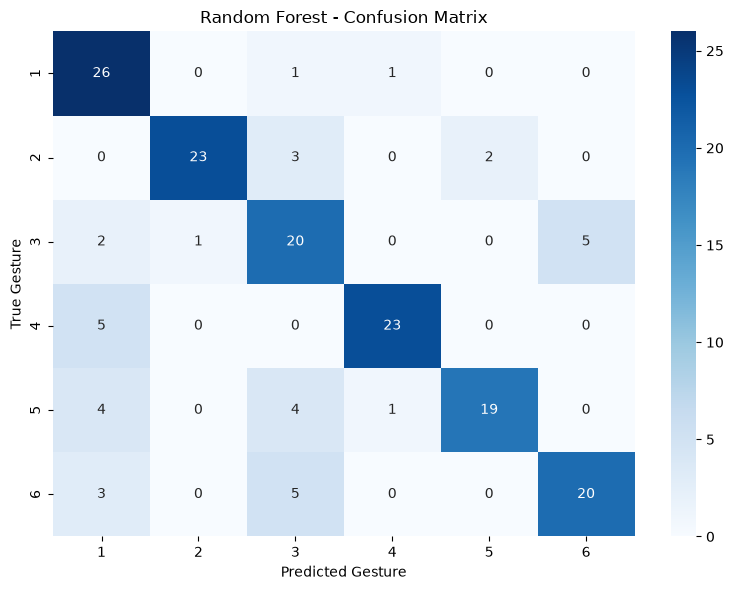


Feature Importance:


,Importance
NE_ch7,0.145856
NE_ch1,0.132908
NE_ch5,0.129920
NE_ch8,0.129259
NE_ch2,0.119918
NE_ch3,0.117313
NE_ch4,0.115162
NE_ch6,0.109662


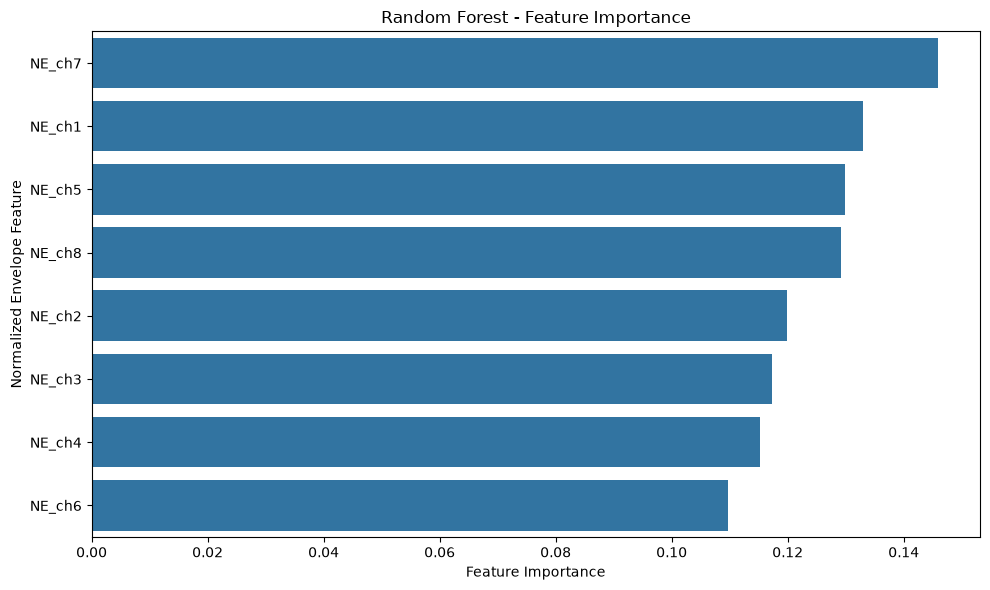

In [2]:
# ============================================================
# EMG HAND GESTURE CLASSIFICATION - RANDOM FOREST
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

channels = [f"channel{i}" for i in range(1, 9)]

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total samples: {len(data):,}")
print(f"Total subjects: {data['label'].nunique()}")
print(f"Gesture classes: {sorted(data['class'].unique())}")


# ============================================================
# 3. IDENTIFY RECORDING SESSIONS
# ============================================================

# Identify when time resets for each subject
data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of each subject starts a new series
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign series number within each subject
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)

print("\nTotal recording sessions:",
      data.groupby(["label", "series"]).ngroups)

print("Sessions per subject:")
print(data.groupby("label")["series"].nunique().value_counts())


# ============================================================
# 4. IDENTIFY INDIVIDUAL GESTURE STROKES
# ============================================================

# A new stroke begins when:
# - The gesture class changes
# - The recording session changes
# - The subject changes

data["new_gesture"] = (
    data["class"].ne(data["class"].shift())
    | data["series"].ne(data["series"].shift())
    | data["label"].ne(data["label"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

print("\nTotal gesture blocks:",
      data["gesture_block"].nunique())


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

feature_rows = []

# Loop through each gesture stroke
for _, group in data.groupby("gesture_block", sort=False):

    stroke = group[channels].to_numpy(dtype=float)

    # Rectify EMG signal
    rectified = np.abs(stroke)

    # Mean Absolute Value
    mav = np.mean(rectified, axis=0)

    # Root Mean Square
    rms = np.sqrt(np.mean(stroke**2, axis=0))

    # Total envelope magnitude
    total_envelope = np.sum(mav)

    # Normalized envelope
    normalized_envelope = mav / (total_envelope + 1e-10)

    # Log total envelope
    log_total_envelope = np.log(total_envelope + 1e-10)

    # Store features
    features = {}

    for ch in range(8):

        features[f"MAV_ch{ch+1}"] = mav[ch]
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"NE_ch{ch+1}"] = normalized_envelope[ch]

    features["Log_Total_Envelope"] = log_total_envelope

    # Store subject, session and gesture class
    features["label"] = group["label"].iloc[0]
    features["series"] = group["series"].iloc[0]
    features["class"] = group["class"].iloc[0]

    feature_rows.append(features)

# Create feature DataFrame
features_df = pd.DataFrame(feature_rows)

print("\n" + "=" * 60)
print("FEATURE EXTRACTION")
print("=" * 60)

print("Feature DataFrame shape:", features_df.shape)
print("Total strokes:", len(features_df))

display(features_df.head())


# ============================================================
# 6. FILTER GESTURE CLASSES
# ============================================================

# Exclude classes 0 and 7
df_model = features_df[
    ~features_df["class"].isin([0, 7])
].copy()

print("\n" + "=" * 60)
print("FILTERED DATASET")
print("=" * 60)

print("Remaining classes:",
      sorted(df_model["class"].unique()))

print("Remaining strokes:", len(df_model))

print("\nStrokes per gesture:")
print(df_model["class"].value_counts().sort_index())


# ============================================================
# 7. SELECT INPUT FEATURES AND TARGET
# ============================================================

# Use 8 normalized envelope features
feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X = df_model[feature_cols]
y = df_model["class"]

# Group by subject
groups = df_model["label"]

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)
print("Number of subjects:", groups.nunique())

assert groups.nunique() == 36, (
    "Expected 36 subjects. Check the subject labels."
)

assert not X.isna().any().any(), (
    "Missing feature values detected."
)

assert np.isfinite(X.to_numpy()).all(), (
    "Non-finite feature values detected."
)


# ============================================================
# 8. SUBJECT-BASED TRAIN/TEST SPLIT (80/20)
# ============================================================

# 29 subjects for training, 7 for testing
# Both sessions from each subject stay together

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_subjects = set(groups.iloc[train_idx])
test_subjects = set(groups.iloc[test_idx])

print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT")
print("=" * 60)

print(f"Training subjects: {len(train_subjects)}")
print(f"Testing subjects:  {len(test_subjects)}")

print(f"\nTraining strokes: {len(X_train)}")
print(f"Testing strokes:  {len(X_test)}")

print(f"\nTraining percentage: {len(X_train)/len(X)*100:.2f}%")
print(f"Testing percentage:  {len(X_test)/len(X)*100:.2f}%")

print("\nTraining subject IDs:", sorted(train_subjects))
print("Testing subject IDs:", sorted(test_subjects))

# Verify no subject overlap
assert train_subjects.isdisjoint(test_subjects), (
    "ERROR: Subjects overlap between training and testing!"
)

print("\nSubject overlap: None")

# Verify all gesture classes appear in both sets
expected_classes = set(y.unique())

assert set(y_train.unique()) == expected_classes, (
    "Some gesture classes are missing from training."
)

assert set(y_test.unique()) == expected_classes, (
    "Some gesture classes are missing from testing."
)

# Class distribution
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int).sort_index()

print("\nClass distribution:")
display(class_distribution)


# ============================================================
# 9. TRAIN RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed.")


# ============================================================
# 10. MODEL PREDICTIONS
# ============================================================

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)


# ============================================================
# 11. MODEL EVALUATION
# ============================================================

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\n" + "=" * 60)
print("RANDOM FOREST PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy:.4f} "
      f"({train_accuracy*100:.2f}%)")

print(f"Testing accuracy:  {test_accuracy:.4f} "
      f"({test_accuracy*100:.2f}%)")

print("\nClassification Report (Test Set):")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()


# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("\nFeature Importance:")
display(importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Normalized Envelope Feature")

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# INITIALIZE MODEL COMPARISON
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Store results from each model
model_results = {}

# Keep the original subject-based split
train_indices = X_train.index
test_indices = X_test.index

MODEL 1: NORMALIZED ENVELOPE
Training accuracy: 1.0
Testing accuracy: 0.7797619047619048

Classification Report:
              precision    recall  f1-score   support

           1       0.65      0.93      0.76        28
           2       0.96      0.82      0.88        28
           3       0.61      0.71      0.66        28
           4       0.92      0.82      0.87        28
           5       0.90      0.68      0.78        28
           6       0.80      0.71      0.75        28

    accuracy                           0.78       168
   macro avg       0.81      0.78      0.78       168
weighted avg       0.81      0.78      0.78       168



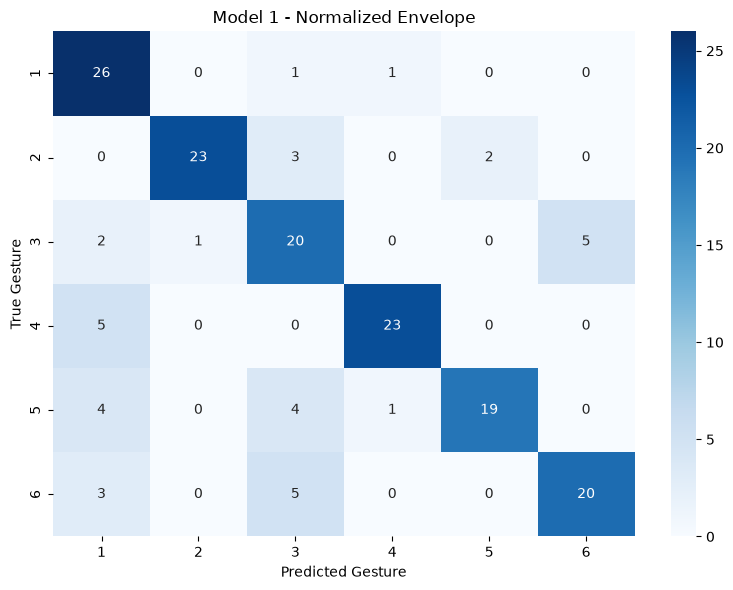

In [4]:
# ============================================================
# MODEL 1: NORMALIZED ENVELOPE
# ============================================================

features_1 = [f"NE_ch{i}" for i in range(1, 9)]

X_train_1 = df_model.loc[train_indices, features_1]
X_test_1 = df_model.loc[test_indices, features_1]

rf_1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1.fit(X_train_1, y_train)

y_train_pred_1 = rf_1.predict(X_train_1)
y_test_pred_1 = rf_1.predict(X_test_1)

model_results["NE"] = {
    "n_features": len(features_1),
    "train_accuracy": accuracy_score(y_train, y_train_pred_1),
    "test_accuracy": accuracy_score(y_test, y_test_pred_1),
    "f1_macro": f1_score(y_test, y_test_pred_1, average="macro")
}

print("MODEL 1: NORMALIZED ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_1))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_1))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_1))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_1),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 1 - Normalized Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 2: MAV
Training accuracy: 1.0
Testing accuracy: 0.8095238095238095

Classification Report:
              precision    recall  f1-score   support

           1       0.90      1.00      0.95        28
           2       0.83      0.86      0.84        28
           3       0.69      0.64      0.67        28
           4       1.00      0.82      0.90        28
           5       0.74      0.89      0.81        28
           6       0.72      0.64      0.68        28

    accuracy                           0.81       168
   macro avg       0.81      0.81      0.81       168
weighted avg       0.81      0.81      0.81       168



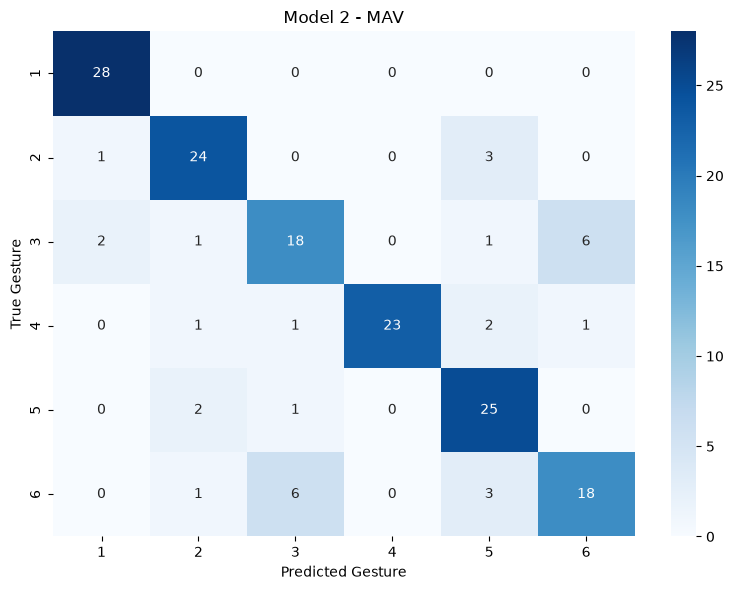

In [5]:
# ============================================================
# MODEL 2: MEAN ABSOLUTE VALUE
# ============================================================

features_2 = [f"MAV_ch{i}" for i in range(1, 9)]

X_train_2 = df_model.loc[train_indices, features_2]
X_test_2 = df_model.loc[test_indices, features_2]

rf_2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train_2, y_train)

y_train_pred_2 = rf_2.predict(X_train_2)
y_test_pred_2 = rf_2.predict(X_test_2)

model_results["MAV"] = {
    "n_features": len(features_2),
    "train_accuracy": accuracy_score(y_train, y_train_pred_2),
    "test_accuracy": accuracy_score(y_test, y_test_pred_2),
    "f1_macro": f1_score(y_test, y_test_pred_2, average="macro")
}

print("MODEL 2: MAV")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_2))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_2))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_2),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 2 - MAV")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 3: RMS
Training accuracy: 1.0
Testing accuracy: 0.8214285714285714

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.92      0.82      0.87        28
           3       0.71      0.71      0.71        28
           4       1.00      0.79      0.88        28
           5       0.68      0.96      0.79        28
           6       0.75      0.64      0.69        28

    accuracy                           0.82       168
   macro avg       0.84      0.82      0.82       168
weighted avg       0.84      0.82      0.82       168



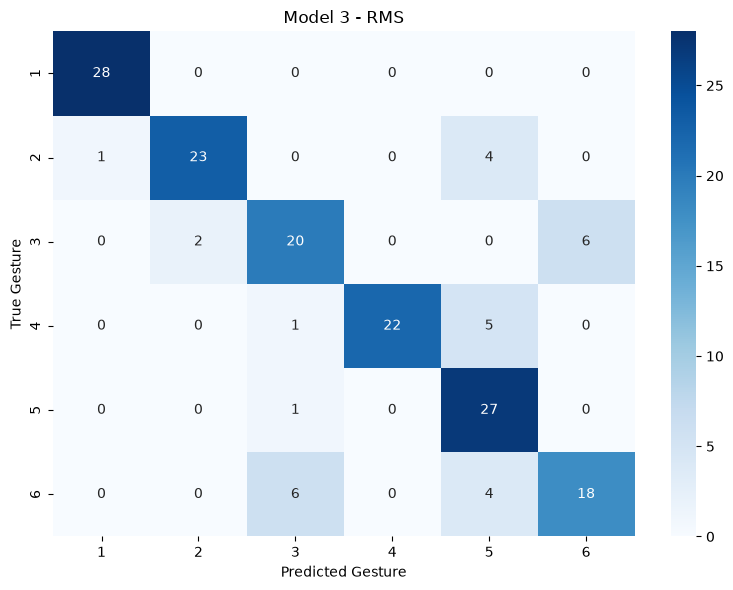

In [6]:
# ============================================================
# MODEL 3: ROOT MEAN SQUARE
# ============================================================

features_3 = [f"RMS_ch{i}" for i in range(1, 9)]

X_train_3 = df_model.loc[train_indices, features_3]
X_test_3 = df_model.loc[test_indices, features_3]

rf_3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_3.fit(X_train_3, y_train)

y_train_pred_3 = rf_3.predict(X_train_3)
y_test_pred_3 = rf_3.predict(X_test_3)

model_results["RMS"] = {
    "n_features": len(features_3),
    "train_accuracy": accuracy_score(y_train, y_train_pred_3),
    "test_accuracy": accuracy_score(y_test, y_test_pred_3),
    "f1_macro": f1_score(y_test, y_test_pred_3, average="macro")
}

print("MODEL 3: RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_3))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_3))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_3),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 3 - RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 4: NE + LOG TOTAL ENVELOPE
Training accuracy: 1.0
Testing accuracy: 0.8273809523809523

Classification Report:
              precision    recall  f1-score   support

           1       0.93      1.00      0.97        28
           2       0.83      0.86      0.84        28
           3       0.70      0.68      0.69        28
           4       1.00      0.86      0.92        28
           5       0.73      0.86      0.79        28
           6       0.80      0.71      0.75        28

    accuracy                           0.83       168
   macro avg       0.83      0.83      0.83       168
weighted avg       0.83      0.83      0.83       168



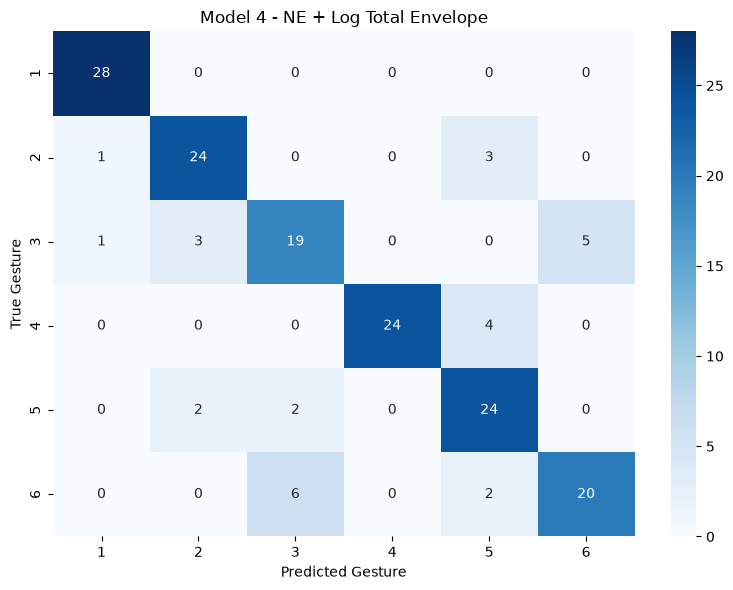

In [7]:
# ============================================================
# MODEL 4: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE
# ============================================================

features_4 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_4 = df_model.loc[train_indices, features_4]
X_test_4 = df_model.loc[test_indices, features_4]

rf_4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_4.fit(X_train_4, y_train)

y_train_pred_4 = rf_4.predict(X_train_4)
y_test_pred_4 = rf_4.predict(X_test_4)

model_results["NE + Log"] = {
    "n_features": len(features_4),
    "train_accuracy": accuracy_score(y_train, y_train_pred_4),
    "test_accuracy": accuracy_score(y_test, y_test_pred_4),
    "f1_macro": f1_score(y_test, y_test_pred_4, average="macro")
}

print("MODEL 4: NE + LOG TOTAL ENVELOPE")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_4))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_4))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_4),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 4 - NE + Log Total Envelope")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 5: MAV + RMS
Training accuracy: 1.0
Testing accuracy: 0.7976190476190477

Classification Report:
              precision    recall  f1-score   support

           1       0.90      1.00      0.95        28
           2       0.66      0.89      0.76        28
           3       0.75      0.64      0.69        28
           4       1.00      0.82      0.90        28
           5       0.78      0.75      0.76        28
           6       0.76      0.68      0.72        28

    accuracy                           0.80       168
   macro avg       0.81      0.80      0.80       168
weighted avg       0.81      0.80      0.80       168



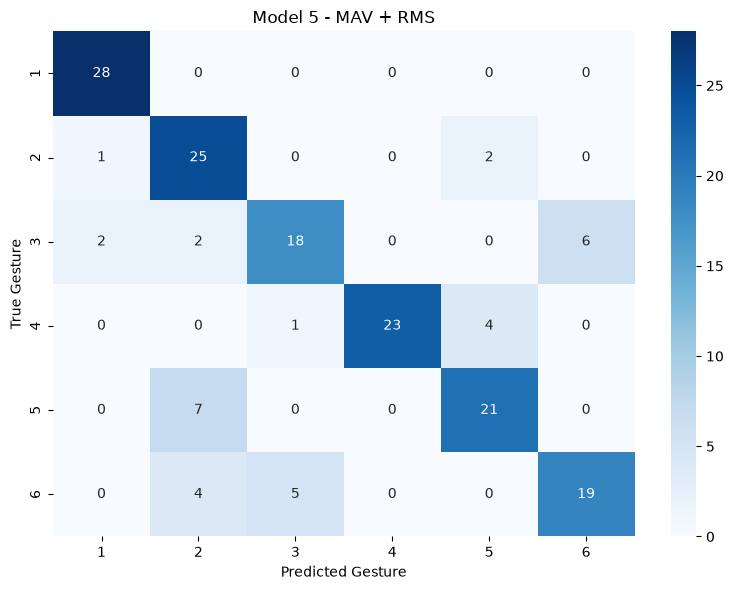

In [8]:
# ============================================================
# MODEL 5: MAV + RMS
# ============================================================

features_5 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_5 = df_model.loc[train_indices, features_5]
X_test_5 = df_model.loc[test_indices, features_5]

rf_5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_5.fit(X_train_5, y_train)

y_train_pred_5 = rf_5.predict(X_train_5)
y_test_pred_5 = rf_5.predict(X_test_5)

model_results["MAV + RMS"] = {
    "n_features": len(features_5),
    "train_accuracy": accuracy_score(y_train, y_train_pred_5),
    "test_accuracy": accuracy_score(y_test, y_test_pred_5),
    "f1_macro": f1_score(y_test, y_test_pred_5, average="macro")
}

print("MODEL 5: MAV + RMS")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_5))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_5))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_5))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_5),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 5 - MAV + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 6: ALL FEATURES
Training accuracy: 1.0
Testing accuracy: 0.8333333333333334

Classification Report:
              precision    recall  f1-score   support

           1       0.93      1.00      0.97        28
           2       0.74      0.93      0.83        28
           3       0.83      0.68      0.75        28
           4       1.00      0.82      0.90        28
           5       0.77      0.86      0.81        28
           6       0.77      0.71      0.74        28

    accuracy                           0.83       168
   macro avg       0.84      0.83      0.83       168
weighted avg       0.84      0.83      0.83       168



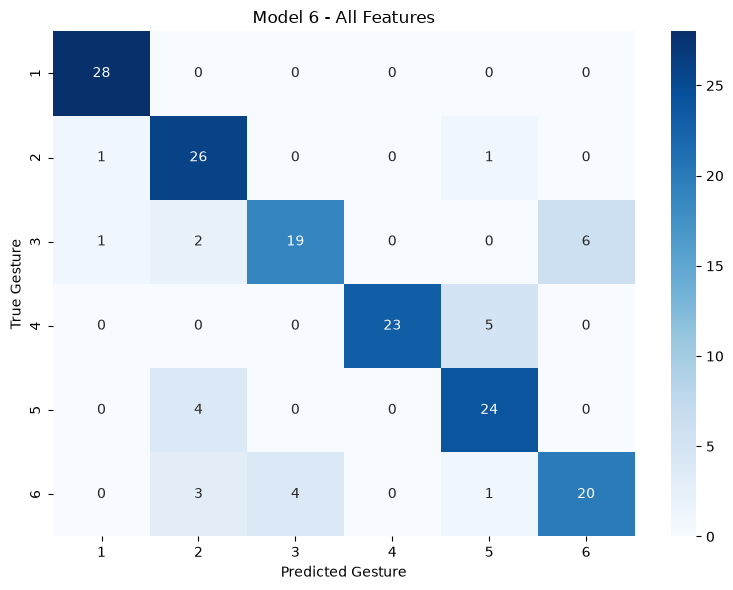

In [15]:
# ============================================================
# MODEL 6: ALL FEATURES
# ============================================================

features_6 = (
    [f"MAV_ch{i}" for i in range(1, 9)]
    + [f"RMS_ch{i}" for i in range(1, 9)]
    + [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
)

X_train_6 = df_model.loc[train_indices, features_6]
X_test_6 = df_model.loc[test_indices, features_6]

rf_6 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_6.fit(X_train_6, y_train)

y_train_pred_6 = rf_6.predict(X_train_6)
y_test_pred_6 = rf_6.predict(X_test_6)

model_results["All Features"] = {
    "n_features": len(features_6),
    "train_accuracy": accuracy_score(y_train, y_train_pred_6),
    "test_accuracy": accuracy_score(y_test, y_test_pred_6),
    "f1_macro": f1_score(y_test, y_test_pred_6, average="macro")
}

print("MODEL 6: ALL FEATURES")
print("Training accuracy:", accuracy_score(y_train, y_train_pred_6))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred_6))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_6))

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_6),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 6 - All Features")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

MODEL 7: NE + LOG TOTAL ENVELOPE + RMS
Training accuracy: 100.00%
Testing accuracy:  82.74%

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.82      0.82      0.82        28
           3       0.79      0.68      0.73        28
           4       1.00      0.86      0.92        28
           5       0.70      0.93      0.80        28
           6       0.73      0.68      0.70        28

    accuracy                           0.83       168
   macro avg       0.84      0.83      0.83       168
weighted avg       0.84      0.83      0.83       168



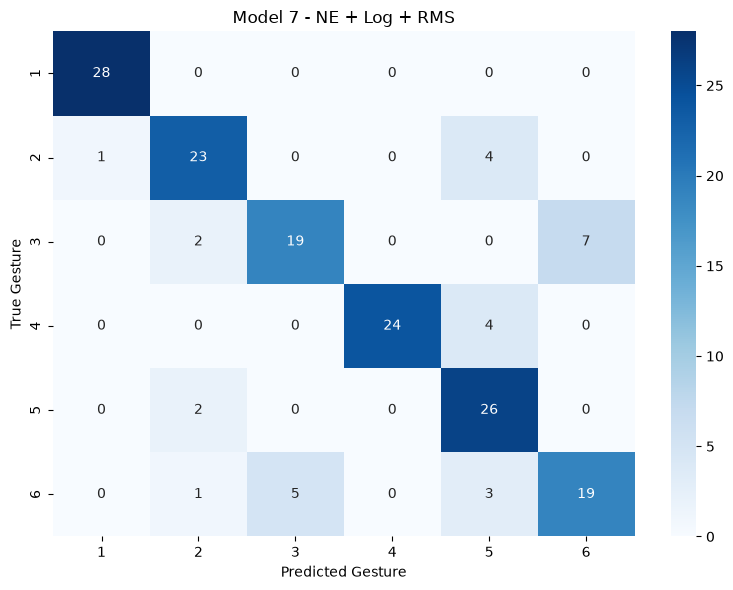

In [19]:
# ============================================================
# MODEL 7: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

features_7 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_7 = df_model.loc[train_indices, features_7]
X_test_7 = df_model.loc[test_indices, features_7]

rf_7 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_7.fit(X_train_7, y_train)

y_train_pred_7 = rf_7.predict(X_train_7)
y_test_pred_7 = rf_7.predict(X_test_7)

model_results["NE + Log + RMS"] = {
    "n_features": len(features_7),
    "train_accuracy": accuracy_score(y_train, y_train_pred_7),
    "test_accuracy": accuracy_score(y_test, y_test_pred_7),
    "f1_macro": f1_score(y_test, y_test_pred_7, average="macro")
}

print("=" * 60)
print("MODEL 7: NE + LOG TOTAL ENVELOPE + RMS")
print("=" * 60)

print(f"Training accuracy: {accuracy_score(y_train, y_train_pred_7)*100:.2f}%")
print(f"Testing accuracy:  {accuracy_score(y_test, y_test_pred_7)*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_7))

# Confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred_7),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Model 7 - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

RANDOM FOREST MODEL COMPARISON


,n_features,train_accuracy,test_accuracy,f1_macro
All Features,25.0,100.0,83.33,83.20
NE + Log,9.0,100.0,82.74,82.72
NE + Log + RMS,17.0,100.0,82.74,82.69
RMS,8.0,100.0,82.14,82.18
MAV,8.0,100.0,80.95,80.76
MAV + RMS,16.0,100.0,79.76,79.69
NE,8.0,100.0,77.98,78.39


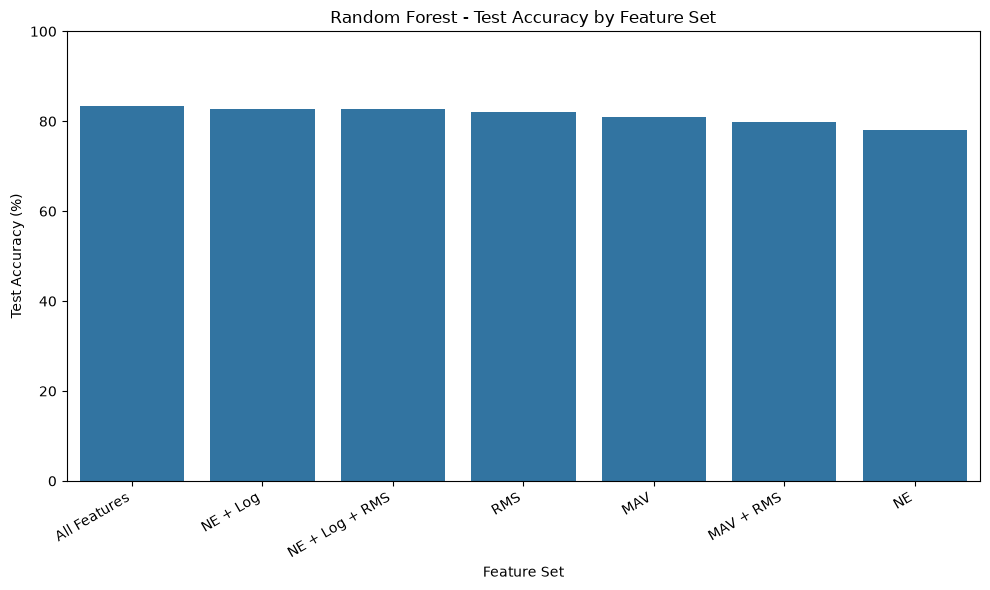

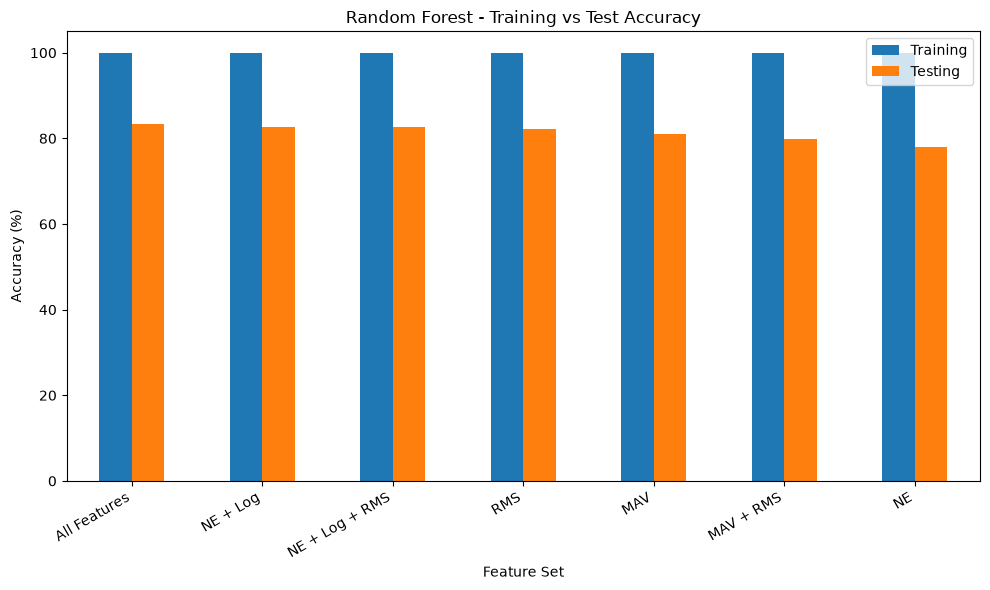

In [13]:
# ============================================================
# RANDOM FOREST MODEL COMPARISON
# ============================================================

# Convert results dictionary into DataFrame
results_df = pd.DataFrame(model_results).T

# Convert accuracy and F1-score to percentages
results_df["train_accuracy"] *= 100
results_df["test_accuracy"] *= 100
results_df["f1_macro"] *= 100

# Sort models by test accuracy
results_df = results_df.sort_values(
    "test_accuracy",
    ascending=False
)

print("=" * 60)
print("RANDOM FOREST MODEL COMPARISON")
print("=" * 60)

display(results_df.round(2))


# ============================================================
# PLOT 1: TEST ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    x=results_df.index,
    y=results_df["test_accuracy"]
)

plt.title("Random Forest - Test Accuracy by Feature Set")
plt.xlabel("Feature Set")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2: TRAINING VS TEST ACCURACY
# ============================================================

accuracy_comparison = results_df[
    ["train_accuracy", "test_accuracy"]
]

accuracy_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest - Training vs Test Accuracy")
plt.xlabel("Feature Set")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.legend(["Training", "Testing"])

plt.tight_layout()
plt.show()


MODEL: NE
Fold 1: Accuracy = 73.61% | F1 = 73.09%
Fold 2: Accuracy = 86.81% | F1 = 86.64%
Fold 3: Accuracy = 68.75% | F1 = 69.30%
Fold 4: Accuracy = 72.92% | F1 = 72.64%
Fold 5: Accuracy = 87.50% | F1 = 87.13%

MODEL: MAV
Fold 1: Accuracy = 80.56% | F1 = 80.57%
Fold 2: Accuracy = 86.11% | F1 = 85.88%
Fold 3: Accuracy = 76.39% | F1 = 76.24%
Fold 4: Accuracy = 81.25% | F1 = 81.45%
Fold 5: Accuracy = 95.83% | F1 = 95.76%

MODEL: RMS
Fold 1: Accuracy = 77.78% | F1 = 77.88%
Fold 2: Accuracy = 83.33% | F1 = 82.83%
Fold 3: Accuracy = 79.86% | F1 = 79.64%
Fold 4: Accuracy = 81.25% | F1 = 81.23%
Fold 5: Accuracy = 94.17% | F1 = 94.10%

MODEL: NE + Log
Fold 1: Accuracy = 77.78% | F1 = 77.62%
Fold 2: Accuracy = 90.28% | F1 = 90.19%
Fold 3: Accuracy = 77.78% | F1 = 77.80%
Fold 4: Accuracy = 84.72% | F1 = 84.66%
Fold 5: Accuracy = 92.50% | F1 = 92.42%

MODEL: MAV + RMS
Fold 1: Accuracy = 81.94% | F1 = 81.69%
Fold 2: Accuracy = 84.72% | F1 = 84.39%
Fold 3: Accuracy = 75.69% | F1 = 75.67%
Fold 4: Ac

,Model,Features,Mean Accuracy (%),Std Accuracy (%),Mean F1 (%)
5,NE + Log + RMS,17,87.06,5.31,87.06
6,All Features,25,84.86,6.34,84.79
3,NE + Log,9,84.61,6.13,84.54
1,MAV,8,84.03,6.66,83.98
2,RMS,8,83.28,5.74,83.14
4,MAV + RMS,16,83.14,6.27,83.03
0,NE,8,77.92,7.73,77.76


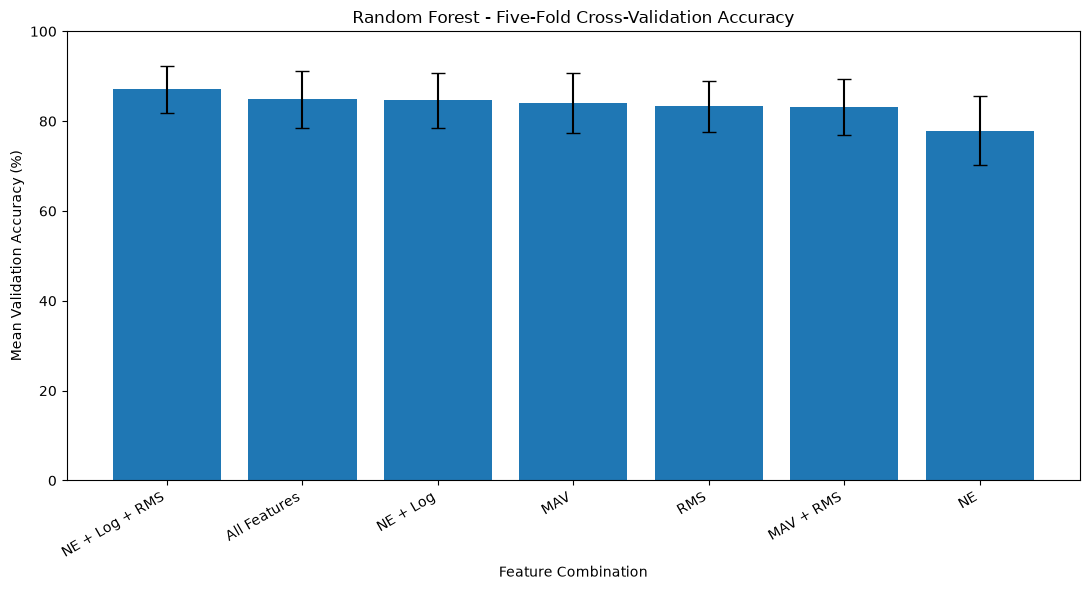

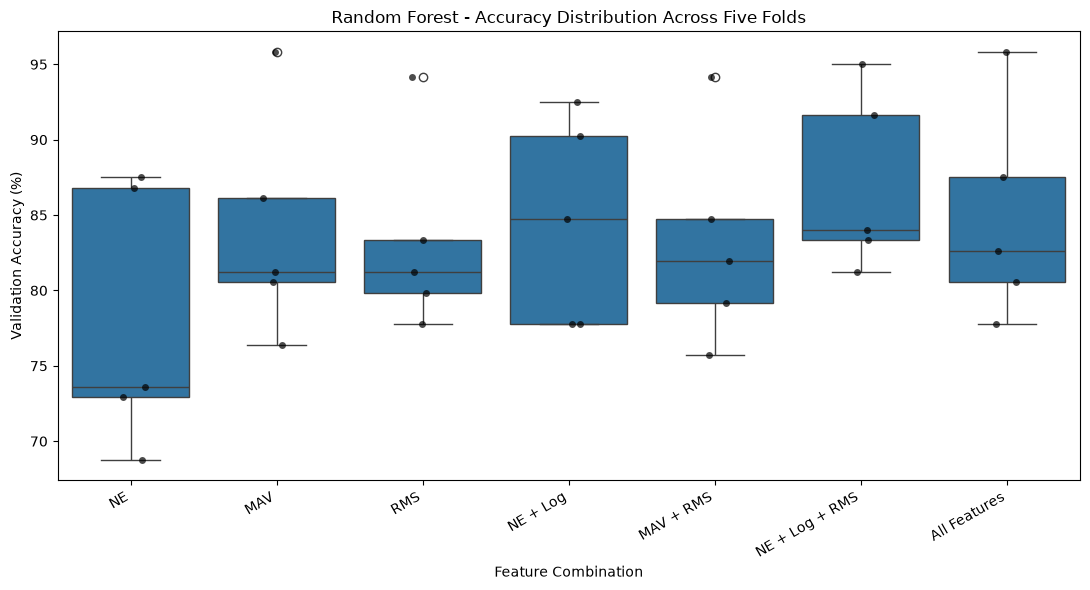

In [14]:
# ============================================================
# FIVE-FOLD GROUP CROSS-VALIDATION
# RANDOM FOREST - ALL FEATURE COMBINATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# 1. DEFINE FEATURE COMBINATIONS
# ============================================================

feature_sets = {
    "NE": [
        f"NE_ch{i}" for i in range(1, 9)
    ],

    "MAV": [
        f"MAV_ch{i}" for i in range(1, 9)
    ],

    "RMS": [
        f"RMS_ch{i}" for i in range(1, 9)
    ],

    "NE + Log": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    ),

    "MAV + RMS": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "NE + Log + RMS": (
        [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
        + [f"RMS_ch{i}" for i in range(1, 9)]
    ),

    "All Features": (
        [f"MAV_ch{i}" for i in range(1, 9)]
        + [f"RMS_ch{i}" for i in range(1, 9)]
        + [f"NE_ch{i}" for i in range(1, 9)]
        + ["Log_Total_Envelope"]
    )
}


# ============================================================
# 2. PREPARE TRAINING DATA
# ============================================================

# Only use the original 29 training subjects
cv_df = df_model.loc[train_indices].copy()

y_cv = cv_df["class"]
groups_cv = cv_df["label"]

# Initialize five-fold grouped cross-validation
gkf = GroupKFold(n_splits=5)

# Store results
cv_results = []
fold_results = []


# ============================================================
# 3. RUN CROSS-VALIDATION
# ============================================================

for model_name, feature_cols in feature_sets.items():

    print("\n" + "=" * 60)
    print(f"MODEL: {model_name}")
    print("=" * 60)

    X_cv = cv_df[feature_cols]

    fold_accuracies = []
    fold_f1_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        gkf.split(X_cv, y_cv, groups=groups_cv),
        start=1
    ):

        # Split data
        X_train_fold = X_cv.iloc[train_idx]
        X_val_fold = X_cv.iloc[val_idx]

        y_train_fold = y_cv.iloc[train_idx]
        y_val_fold = y_cv.iloc[val_idx]

        # Verify no subject overlap
        train_groups = set(groups_cv.iloc[train_idx])
        val_groups = set(groups_cv.iloc[val_idx])

        assert train_groups.isdisjoint(val_groups)

        # Create model
        rf = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

        # Train model
        rf.fit(X_train_fold, y_train_fold)

        # Predict validation set
        y_pred_fold = rf.predict(X_val_fold)

        # Calculate metrics
        accuracy = accuracy_score(
            y_val_fold, y_pred_fold
        )

        f1 = f1_score(
            y_val_fold,
            y_pred_fold,
            average="macro"
        )

        fold_accuracies.append(accuracy)
        fold_f1_scores.append(f1)

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy * 100,
            "F1 Macro": f1 * 100
        })

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy*100:.2f}% | "
            f"F1 = {f1*100:.2f}%"
        )

    # Store summary
    cv_results.append({
        "Model": model_name,
        "Features": len(feature_cols),
        "Mean Accuracy (%)": np.mean(fold_accuracies) * 100,
        "Std Accuracy (%)": np.std(fold_accuracies) * 100,
        "Mean F1 (%)": np.mean(fold_f1_scores) * 100
    })


# ============================================================
# 4. CREATE RESULTS DATAFRAMES
# ============================================================

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean Accuracy (%)",
    ascending=False
)

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 60)
print("CROSS-VALIDATION MODEL COMPARISON")
print("=" * 60)

display(cv_results_df.round(2))


# ============================================================
# 5. PLOT MEAN CROSS-VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(11, 6))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean Accuracy (%)"],
    yerr=cv_results_df["Std Accuracy (%)"],
    capsize=5
)

plt.title("Random Forest - Five-Fold Cross-Validation Accuracy")
plt.xlabel("Feature Combination")
plt.ylabel("Mean Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# 6. PLOT ACCURACY DISTRIBUTION ACROSS FOLDS
# ============================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy"
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="Accuracy",
    color="black",
    alpha=0.7
)

plt.title("Random Forest - Accuracy Distribution Across Five Folds")
plt.xlabel("Feature Combination")
plt.ylabel("Validation Accuracy (%)")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

SVM training completed.

SVM PERFORMANCE
Training accuracy: 88.22%
Testing accuracy:  76.79%
Macro F1-score:    0.7724

Classification Report:
              precision    recall  f1-score   support

           1       0.57      0.86      0.69        28
           2       0.86      0.86      0.86        28
           3       0.73      0.68      0.70        28
           4       0.96      0.79      0.86        28
           5       0.87      0.71      0.78        28
           6       0.77      0.71      0.74        28

    accuracy                           0.77       168
   macro avg       0.79      0.77      0.77       168
weighted avg       0.79      0.77      0.77       168



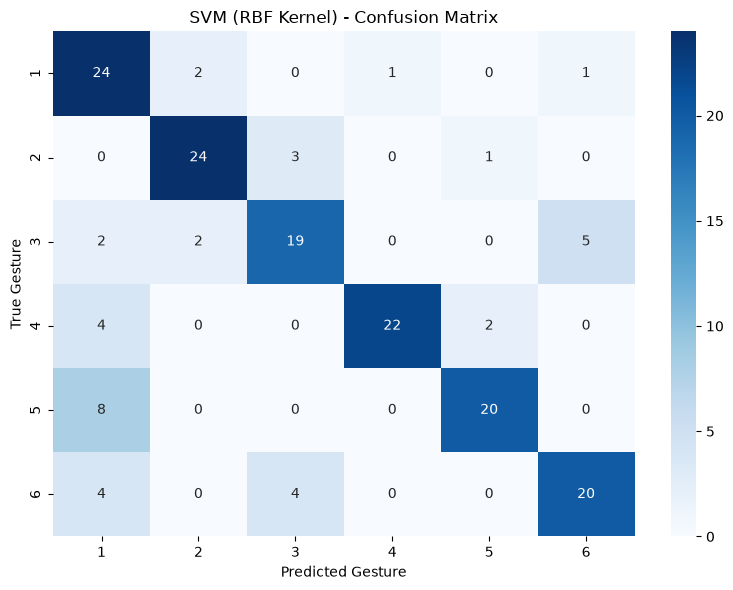

In [20]:
# ============================================================
# SVM MODEL: NORMALIZED ENVELOPE
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

feature_cols = [f"NE_ch{i}" for i in range(1, 9)]

X_train_svm = df_model.loc[X_train.index, feature_cols]
X_test_svm = df_model.loc[X_test.index, feature_cols]


# ============================================================
# 2. CREATE SVM PIPELINE
# ============================================================

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])


# ============================================================
# 3. TRAIN MODEL
# ============================================================

svm_model.fit(X_train_svm, y_train)

print("SVM training completed.")


# ============================================================
# 4. MAKE PREDICTIONS
# ============================================================

y_train_pred_svm = svm_model.predict(X_train_svm)
y_test_pred_svm = svm_model.predict(X_test_svm)


# ============================================================
# 5. EVALUATE MODEL
# ============================================================

train_accuracy_svm = accuracy_score(
    y_train, y_train_pred_svm
)

test_accuracy_svm = accuracy_score(
    y_test, y_test_pred_svm
)

f1_macro_svm = f1_score(
    y_test, y_test_pred_svm, average="macro"
)

print("\n" + "=" * 60)
print("SVM PERFORMANCE")
print("=" * 60)

print(f"Training accuracy: {train_accuracy_svm*100:.2f}%")
print(f"Testing accuracy:  {test_accuracy_svm*100:.2f}%")
print(f"Macro F1-score:    {f1_macro_svm:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_svm))


# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF Kernel) - Confusion Matrix")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()

SVM - NE + LOG + RMS
Training accuracy: 94.68%
Testing accuracy: 79.17%
Macro F1-score: 0.7963

Classification Report:
              precision    recall  f1-score   support

           1       0.90      0.96      0.93        28
           2       0.80      0.71      0.75        28
           3       0.54      0.71      0.62        28
           4       1.00      0.86      0.92        28
           5       0.85      0.82      0.84        28
           6       0.76      0.68      0.72        28

    accuracy                           0.79       168
   macro avg       0.81      0.79      0.80       168
weighted avg       0.81      0.79      0.80       168



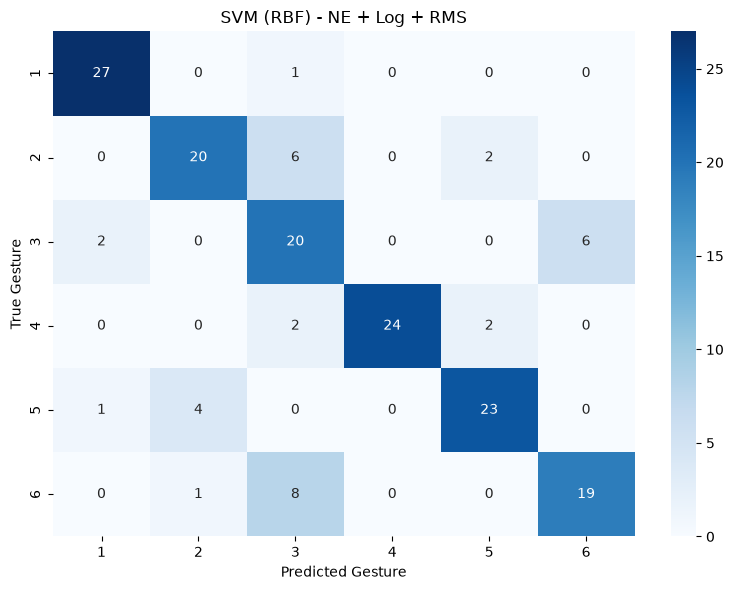

In [21]:
# ============================================================
# SVM: NORMALIZED ENVELOPE + LOG TOTAL ENVELOPE + RMS
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. SELECT FEATURES
# ============================================================

features_svm_17 = (
    [f"NE_ch{i}" for i in range(1, 9)]
    + ["Log_Total_Envelope"]
    + [f"RMS_ch{i}" for i in range(1, 9)]
)

X_train_svm_17 = df_model.loc[
    train_indices, features_svm_17
]

X_test_svm_17 = df_model.loc[
    test_indices, features_svm_17
]


# ============================================================
# 2. CREATE AND TRAIN SVM
# ============================================================

svm_17 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_17.fit(X_train_svm_17, y_train)


# ============================================================
# 3. PREDICTIONS
# ============================================================

y_train_pred = svm_17.predict(X_train_svm_17)
y_test_pred = svm_17.predict(X_test_svm_17)


# ============================================================
# 4. EVALUATION
# ============================================================

print("=" * 60)
print("SVM - NE + LOG + RMS")
print("=" * 60)

print(
    f"Training accuracy: "
    f"{accuracy_score(y_train, y_train_pred)*100:.2f}%"
)

print(
    f"Testing accuracy: "
    f"{accuracy_score(y_test, y_test_pred)*100:.2f}%"
)

print(
    f"Macro F1-score: "
    f"{f1_score(y_test, y_test_pred, average='macro'):.4f}"
)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM (RBF) - NE + Log + RMS")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()